# **Cluster Generation**

In [1]:
!pip install pennylane
!pip install networks
!pip install pennylane-lightning[gpu]

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.5/51.5 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 46.2 MB/s eta 0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
  Preparing metadata (setup.py) ... done
  Created wheel for networks: filename=networks-0.3.7-py3-none-any.whl size=11677 sha256=c1810ddee7d7915687d19706abaa5f4c765d7067208bee6d9b4504138f7adf9d
  Stored in dire

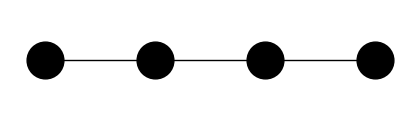

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 4  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(4, 1))
nx.draw(G, pos={node: node for node in G}, node_size=700, node_color="black")

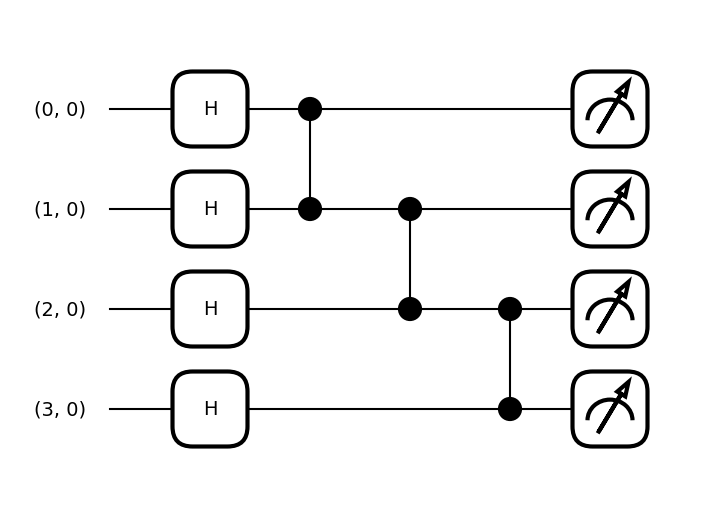

In [3]:
import pennylane as qml

qubits = [str(node) for node in G.nodes()]
dev = qml.device("lightning.qubit", wires=qubits)

@qml.qnode(dev, interface='autograd')
def cluster_state():
   for node in qubits:
       qml.Hadamard(wires=[node])
   for edge in G.edges:
      i, j = edge
      qml.CZ(wires=[str(i), str(j)])

   return qml.state()

fig = qml.draw_mpl(cluster_state, expansion_strategy="device")()
plt.show()

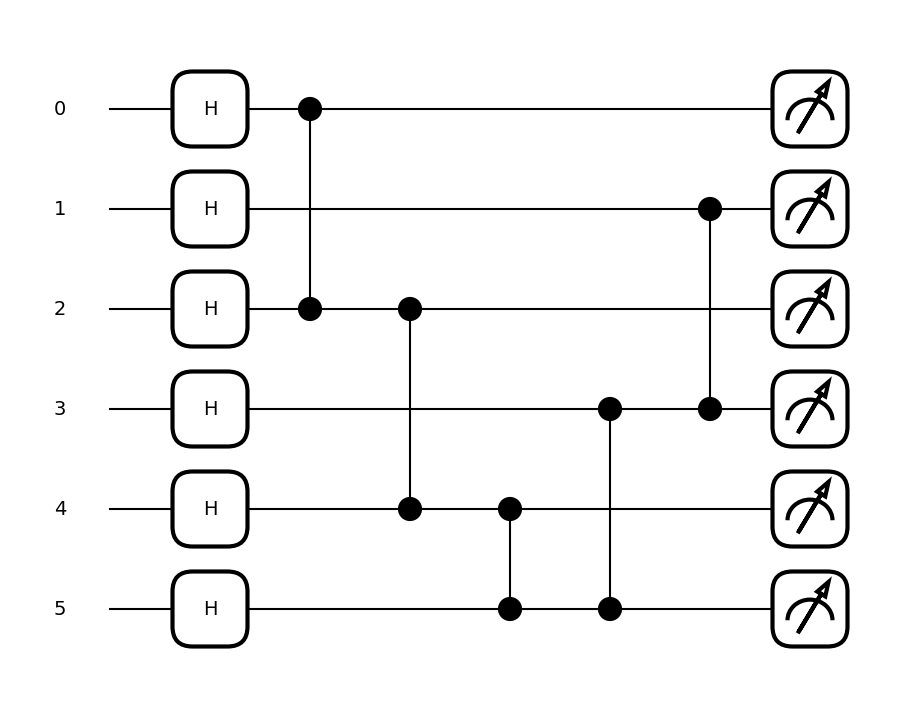

In [4]:
import pennylane as qml
import matplotlib.pyplot as plt

# Device
dev = qml.device("lightning.qubit", wires=5)

# QNode to prepare 3-qubit cluster state
@qml.qnode(dev)
def cluster_state():
    # Initialize all qubits to |+> state
    for i in range(6):
        qml.Hadamard(wires=i)

    # Apply CZ gates according to cluster
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[4, 5])
    qml.CZ(wires=[5, 3])
    qml.CZ(wires=[3, 1])

    return qml.state()

# Get the state
# state = cluster_state()
# print("Cluster state vector:")
# print(state)

# Optional: draw circuit
fig, ax = qml.draw_mpl(cluster_state)()
plt.show()


# **Information Propagation (Quantum Teleportation)**

In [5]:
import pennylane as qml
import numpy as np

def state_preparation(state):
  qml.StatePrep(state, wires=["S"])

def entangle_qubits():
  qml.Hadamard(wires="A")
  qml.CNOT(wires=["A", "B"])

def basis_rotation():
  qml.CNOT(wires=["S", "A"])
  qml.Hadamard(wires="S")

def measure_and_update():
  m0 = qml.measure("S")
  m1 = qml.measure("A")
  qml.cond(m1, qml.PauliX)("B")
  qml.cond(m0, qml.PauliZ)("B")

def teleport(state):
    state_preparation(state)
    entangle_qubits()
    basis_rotation()
    measure_and_update()

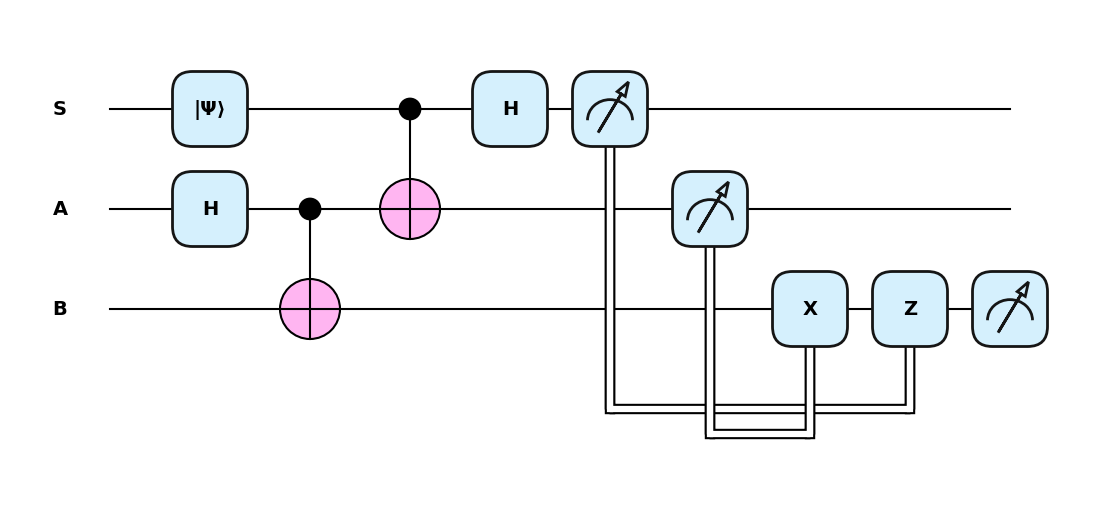

In [7]:
state = np.array([1 / np.sqrt(2) + 0.3j, 0.4 - 0.5j])
_ = qml.draw_mpl(teleport, style="pennylane")(state)

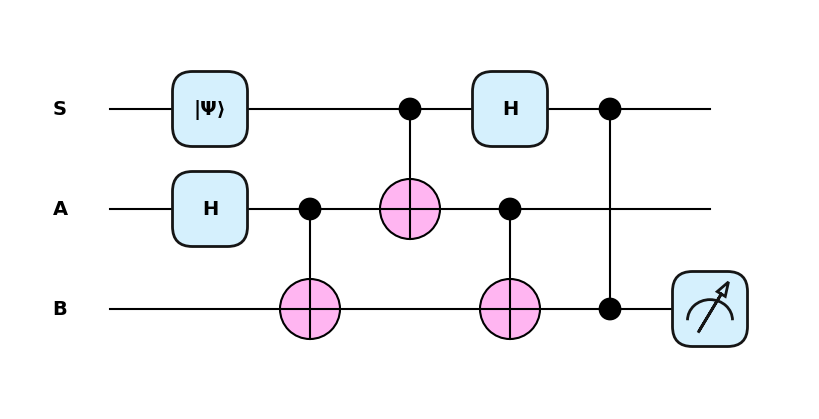

In [8]:
dev = qml.device("default.qubit", wires=["S", "A", "B"])


@qml.qnode(dev)
def teleport(state):
    state_preparation(state)
    entangle_qubits()
    basis_rotation()
    measure_and_update()
    return qml.density_matrix(wires=["B"])


_ = qml.draw_mpl(teleport, style="pennylane", level="device")(state)

In [9]:
def teleport_state(state):
    teleported_density_matrix = teleport(state)
    original_density_matrix = qml.math.dm_from_state_vector(state)

    if not np.allclose(teleported_density_matrix, original_density_matrix):
        raise ValueError(
            f"Alice's state ({state}) not teleported properly. "
            f"Final density matrix of Bob's subsystem: {teleported_density_matrix}"
        )
    print("State successfully teleported!")


teleport_state(state)

State successfully teleported!


## Single Qubit Rotations

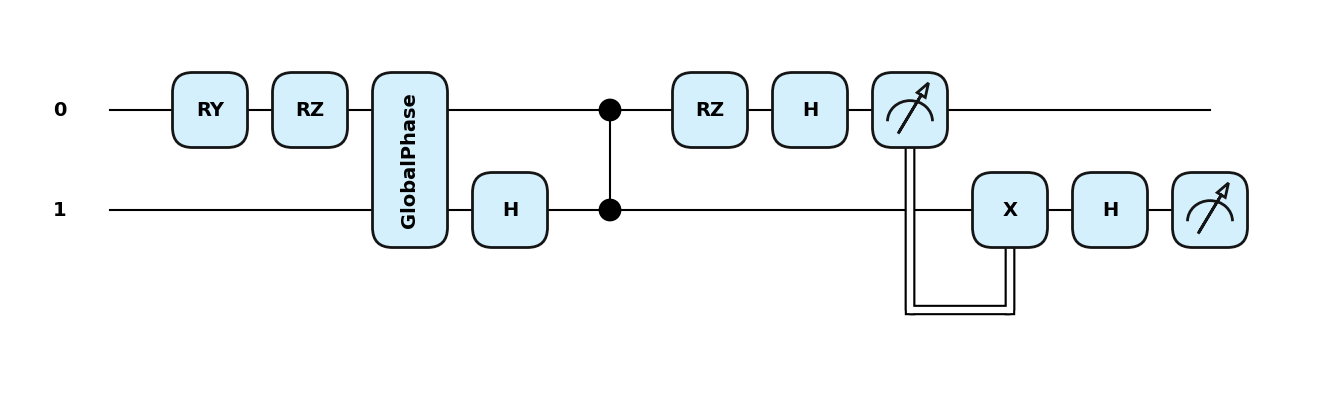

In [10]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

mbqc_dev = qml.device("lightning.qubit", wires=2)

@qml.qnode(mbqc_dev, interface="autograd")
def RZ_MBQC(theta, input_state):
    qml.StatePrep(input_state, wires=0)
    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    qml.RZ(theta, wires=0)
    qml.Hadamard(wires=0)
    m = qml.measure(wires=[0])

    qml.cond(m == 1, qml.PauliX)(wires=1)
    qml.Hadamard(wires=1)

    return qml.density_matrix(wires=[1])

# Define parameters
theta = np.pi / 4
input_state = np.array([1, 0])  # |0⟩ state


# Plot circuit
qml.drawer.draw_mpl(RZ_MBQC, style="pennylane")(theta, input_state)
plt.show()


In [11]:
# Define helper function for random input state on n qubits
def generate_random_state(n=1):
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)

input_state = generate_random_state()
theta = 2 * np.pi * np.random.random()

RZ_MBQC(theta, input_state)

array([[ 0.36239607+0.j        , -0.31605475+0.36218028j],
       [-0.31605475-0.36218028j,  0.63760393+0.j        ]])

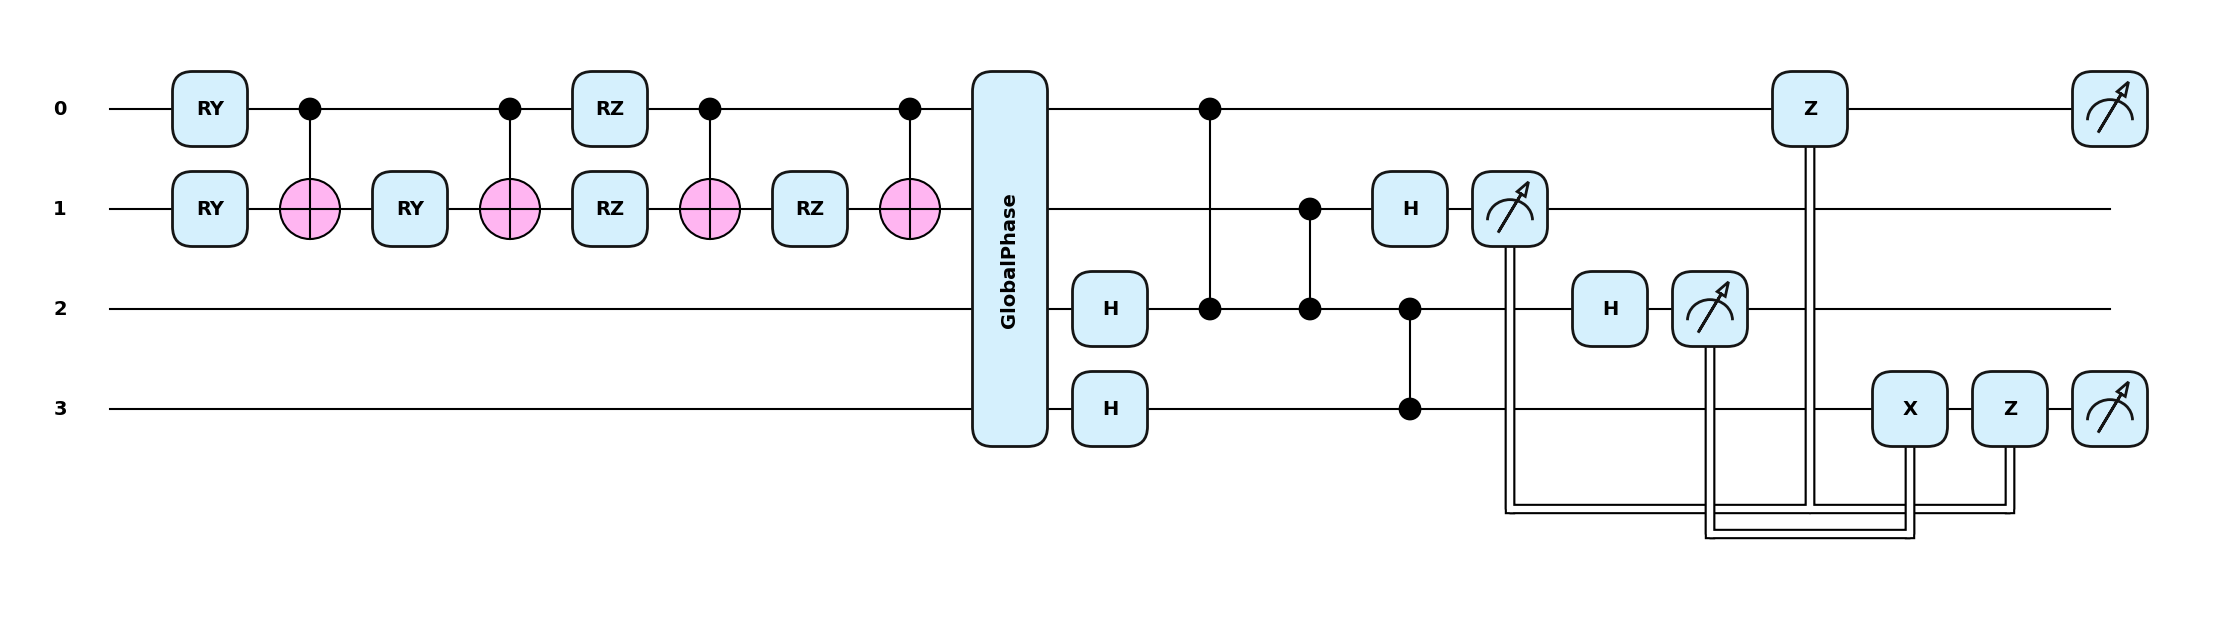

In [12]:
dev = qml.device("lightning.qubit", wires=2)


@qml.qnode(dev, interface="autograd")
def CNOT(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=[0, 1])
    qml.CNOT(wires=[0, 1])

    return qml.density_matrix(wires=[0, 1])


mbqc_dev = qml.device("lightning.qubit", wires=4)


@qml.qnode(mbqc_dev, interface="autograd")
def CNOT_MBQC(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare the cluster state
    qml.Hadamard(wires=2)
    qml.Hadamard(wires=3)
    qml.CZ(wires=[2, 0])
    qml.CZ(wires=[2, 1])
    qml.CZ(wires=[2, 3])

    # Measure the qubits in the appropriate bases
    qml.Hadamard(wires=1)
    m1 = qml.measure(wires=[1])
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=[2])

    # Correct the state
    qml.cond(m1 == 1, qml.PauliZ)(wires=0)
    qml.cond(m2 == 1, qml.PauliX)(wires=3)
    qml.cond(m1 == 1, qml.PauliZ)(wires=3)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0, 3])


# Define helper function for random input state on n qubits
def generate_random_state(n=1):
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)


input_state = generate_random_state(n=2)


# Plot circuit
qml.drawer.draw_mpl(CNOT_MBQC, style="pennylane")(input_state)
plt.show()


#**Linear Cluster Test**

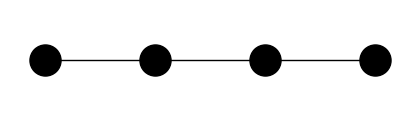

In [13]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 4  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(4, 1))
nx.draw(G, pos={node: node for node in G}, node_size=500, node_color="black")

In [14]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt

def generate_random_state(n=1):
  input_state = np.random.random(2 ** n) + 1j * np.random.random(2**n)
  return input_state / np.linalg.norm(input_state)

input_state = generate_random_state()
density_matrix = np.outer(input_state, np.conj(input_state))

print(input_state)
print(density_matrix)

[0.69336937+0.63896274j 0.3206912 +0.09012598j]
[[0.88903446+6.03451054e-18j 0.2799446 +1.42419137e-01j]
 [0.2799446 -1.42419137e-01j 0.11096554+1.55638808e-18j]]


In [15]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Generate random pure state and corresponding density matrix
def generate_random_state(n=1):
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)

input_state = generate_random_state()
density_matrix = np.outer(input_state, np.conj(input_state))

In [16]:
dev = qml.device("lightning.qubit", wires=1)

@qml.qnode(dev, interface='autograd')

def RX(theta, input_state):
  qml.StatePrep(input_state, wires=0)
  qml.RX(theta, wires=0)
  return qml.density_matrix(wires=[0])

## RX Gate

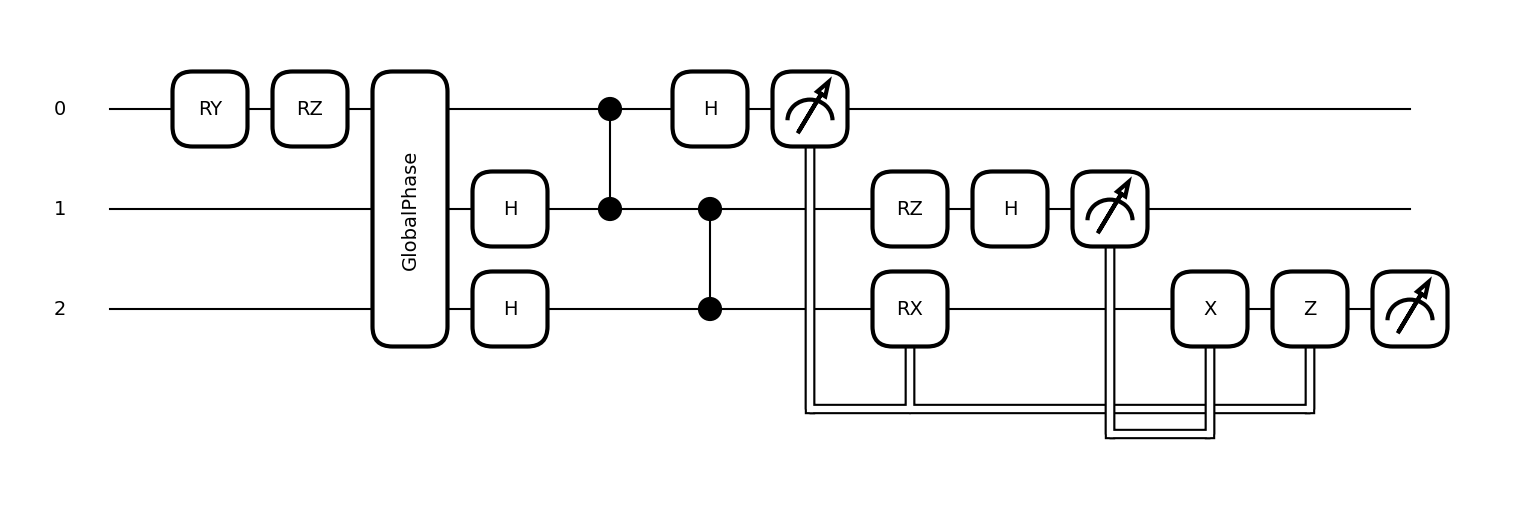

In [17]:
dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def RX(theta, input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.RX(theta, wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])


mbqc_dev = qml.device("lightning.qubit", wires=3)

# Define the QNode
@qml.qnode(mbqc_dev, interface="autograd")
def RX_MBQC(theta, input_state):
    qml.StatePrep(input_state, wires=0)

    # Create cluster state
    qml.Hadamard(wires=1)
    qml.Hadamard(wires=2)
    qml.CZ(wires=[0, 1])
    qml.CZ(wires=[1, 2])

    # Measurement-based RX
    qml.Hadamard(wires=0)
    m1 = qml.measure(wires=0)

    qml.RZ(theta, wires=1)
    qml.cond(m1 == 1, qml.RX)(-2 * theta, wires=2)
    qml.Hadamard(wires=1)
    m2 = qml.measure(wires=1)

    qml.cond(m2 == 1, qml.PauliX)(wires=2)
    qml.cond(m1 == 1, qml.PauliZ)(wires=2)

    return qml.density_matrix(wires=2)

# Define example inputs
theta = np.pi / 4
input_state = np.array([1.0, 0.0], dtype=complex)

# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(RX_MBQC)(theta, input_state)
plt.show()

In [18]:
# Generate a random input state
input_state = generate_random_state()
theta = 2 * np.pi * np.random.random()

np.allclose(RX(theta, input_state), RX_MBQC(theta, input_state))

True

In [19]:
# --- Inputs ---
theta = np.pi / 4
input_state = np.array([1.0, 0.0], dtype=complex)

# --- Compute density matrices ---
rho_rx = RX(theta, input_state)
rho_mbqc = RX_MBQC(theta, input_state)

# --- Display results ---
np.set_printoptions(precision=3, suppress=True)
print("Density Matrix (Standard RX):")
print(rho_rx)

print("\nDensity Matrix (MBQC RX):")
print(rho_mbqc)

Density Matrix (Standard RX):
[[0.854+0.j    0.   +0.354j]
 [0.   -0.354j 0.146+0.j   ]]

Density Matrix (MBQC RX):
[[0.854+0.j    0.   +0.354j]
 [0.   -0.354j 0.146+0.j   ]]


# **Different Gates**

## **2 Qubit**

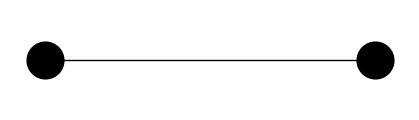

In [20]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 2  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(4, 1))
nx.draw(G, pos={node: node for node in G}, node_size=700, node_color="black")

## **Example of Combining RZ_MBQC function With Graph State**

[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]


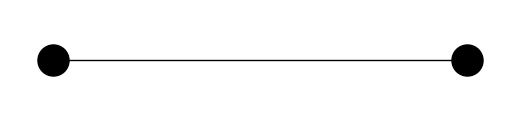

In [21]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 2  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(5, 1))
nx.draw(G, pos={node: node for node in G}, node_size=500, node_color="black")


import pennylane as qml
import numpy as np

qubits = [str(node) for node in G.nodes]
dev = qml.device("lightning.qubit", wires=qubits)

@qml.qnode(dev, interface="autograd")
def cluster_state_RZ(input_state, theta):
    for edge in G.edges:
        i, j = edge
        qml.StatePrep(input_state,wires=[str(i)])
        qml.Hadamard(wires=[str(j)])
        qml.CZ(wires=[str(i), str(j)])
        qml.RZ(theta, wires=[str(i)])
        qml.Hadamard(wires=[str(i)])

        m = qml.measure(wires=[str(i)])

        qml.cond(m == 1, qml.PauliX)(wires=[str(j)])
        qml.Hadamard(wires=[str(j)])


    return qml.density_matrix(wires=[str(j)])

theta = np.pi / 4
input_state = np.array([1.0, 0.0], dtype=complex)

print(cluster_state_RZ(input_state, theta))


dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def RZ(theta, input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.RZ(theta, wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])

theta = np.pi / 4
input_state = np.array([1.0, 0.0], dtype=complex)

print(RZ(theta, input_state))

## **RZ Gate**

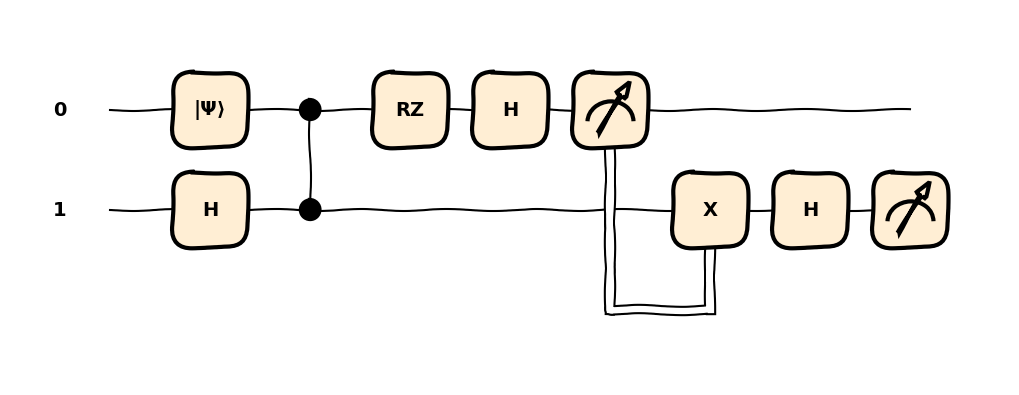

In [22]:
dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def RZ(theta, input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.RZ(theta, wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])


mbqc_dev = qml.device("lightning.qubit", wires=2)


@qml.qnode(mbqc_dev, interface="autograd")
def RZ_MBQC(theta, input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    # Measure the first qubit and correct the state
    qml.RZ(theta, wires=0)
    qml.Hadamard(wires=0)
    m = qml.measure(wires=[0])

    qml.cond(m == 1, qml.PauliX)(wires=1)
    qml.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[1])


# # Define example inputs
# theta = np.pi / 4
# input_state = np.array([1.0, 0.0], dtype=complex)

# Generate a random input state
input_state = generate_random_state()
theta = np.pi/4

# print(RZ(theta, input_state))
# print(RZ_MBQC(theta, input_state))

# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(RZ_MBQC, style='sketch')(theta, input_state)
plt.show()


# np.allclose(RZ(theta, input_state), RZ_MBQC(theta, input_state))

array([[1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j]])

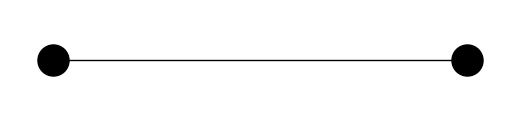

In [23]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 2  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(5, 1))
nx.draw(G, pos={node: node for node in G}, node_size=500, node_color="black")


import pennylane as qml
import numpy as np

qubits = [str(node) for node in G.nodes]
dev = qml.device("lightning.qubit", wires=qubits)

@qml.qnode(dev, interface="autograd")
def cluster_state_RZ(input_state, theta):
    for edge in G.edges:
        i, j = edge
        qml.StatePrep(input_state,wires=[str(i)])
        qml.Hadamard(wires=[str(j)])
        qml.CZ(wires=[str(i), str(j)])
        qml.RZ(theta, wires=[str(i)])
        qml.Hadamard(wires=[str(i)])

        m = qml.measure(wires=[str(i)])

        qml.cond(m == 1, qml.PauliX)(wires=[str(j)])
        qml.Hadamard(wires=[str(j)])


    return qml.density_matrix(wires=[str(j)])

theta = np.pi / 2
input_state = np.array([1.0, 0.0], dtype=complex)

cluster_state_RZ(input_state, theta)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


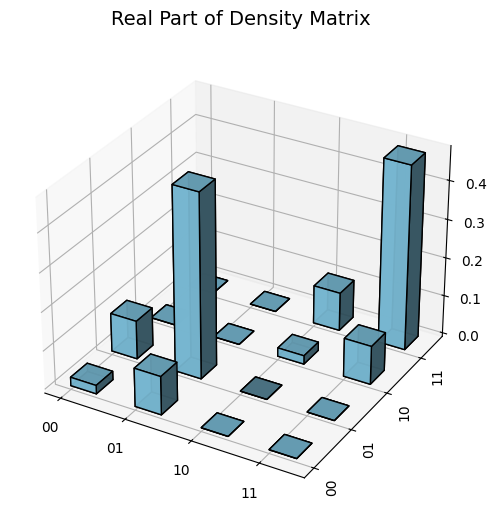

In [24]:
import pennylane as qml
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Set up the device that supports density matrix and mid-circuit measurement
dev = qml.device("default.qubit", wires=3)

# Generate random normalized state
def generate_random_state():
    vec = np.random.randn(2) + 1j * np.random.randn(2)
    vec /= np.linalg.norm(vec)
    return np.array(vec, dtype=complex)

# Define the MBQC circuit
@qml.qnode(dev, interface="autograd")
def RZ_MBQC(theta, input_state):
    qml.StatePrep(input_state, wires=0)

    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    qml.RZ(theta, wires=0)
    qml.Hadamard(wires=0)
    m = qml.measure(wires=0)

    qml.cond(m == 1, qml.PauliX)(wires=1)
    qml.Hadamard(wires=1)

    return qml.density_matrix(wires=[0, 1])


def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state()
theta =  np.pi /2
rho = RZ_MBQC(theta, input_state)

plot_density_matrix_3d_simple(rho)

# print(rho)



## **Hadamard Gate Like Functionality**

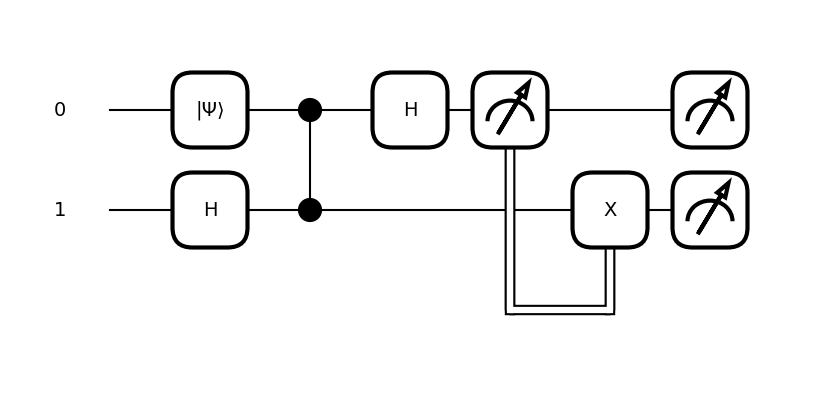

[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
[[0.25+0.j 0.25+0.j 0.  +0.j 0.  +0.j]
 [0.25+0.j 0.25+0.j 0.  +0.j 0.  +0.j]
 [0.  +0.j 0.  +0.j 0.25+0.j 0.25+0.j]
 [0.  +0.j 0.  +0.j 0.25+0.j 0.25+0.j]]


tensor([[0.25+0.j, 0.25+0.j, 0.  +0.j, 0.  +0.j],
        [0.25+0.j, 0.25+0.j, 0.  +0.j, 0.  +0.j],
        [0.  +0.j, 0.  +0.j, 0.25+0.j, 0.25+0.j],
        [0.  +0.j, 0.  +0.j, 0.25+0.j, 0.25+0.j]], requires_grad=True)

In [80]:
dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def H(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.Hadamard(wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])

mbqc_dev = qml.device("default.qubit", wires=3)


@qml.qnode(mbqc_dev, interface="autograd")
def H_MBQC(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    # Measure the first qubit and correct the state
    qml.Hadamard(wires=0)
    m = qml.measure(wires=[0])

    qml.cond(m == 1, qml.PauliX)(wires=1)
    # qml.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0,1])



input_state = np.array([1.0, 0.0], dtype=complex)

# Generate a random input state


# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(H_MBQC)(input_state)
plt.show()

print(H(input_state))
print(H_MBQC(input_state))


H_MBQC(input_state)

# np.allclose(H(input_state), H_MBQC(input_state)) # reduced the density matrix to check for mbqc H

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


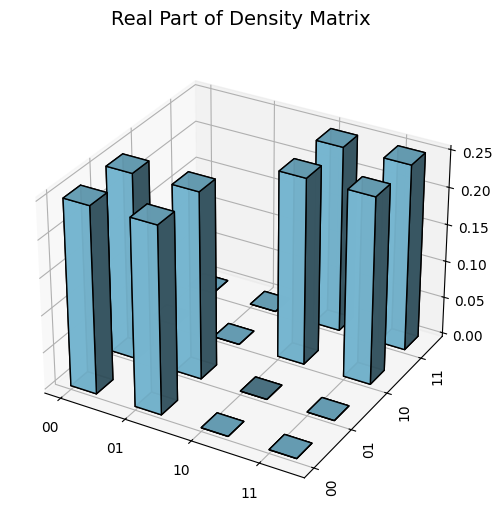

[[0.25+0.j 0.25+0.j 0.  +0.j 0.  +0.j]
 [0.25+0.j 0.25+0.j 0.  +0.j 0.  +0.j]
 [0.  +0.j 0.  +0.j 0.25+0.j 0.25+0.j]
 [0.  +0.j 0.  +0.j 0.25+0.j 0.25+0.j]]


In [81]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
# input_state = generate_random_state()

rho = H_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)


## **T Gate Like Functionality**

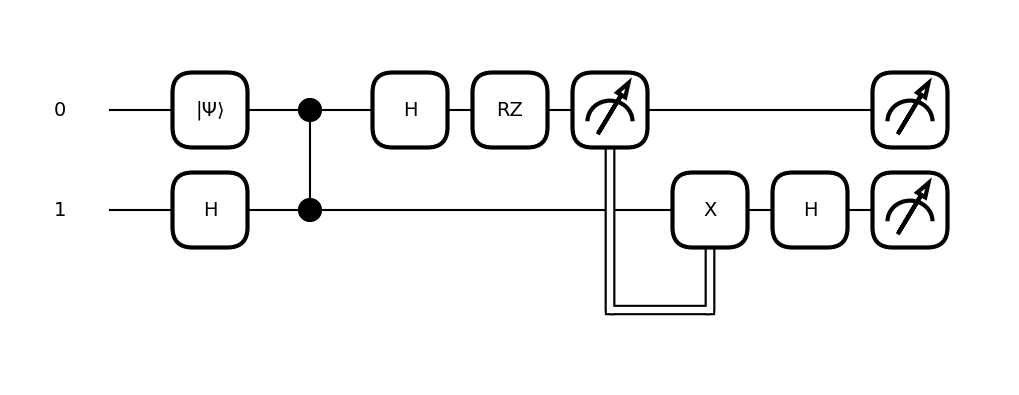

[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
[[0.5+0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0.5+0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]]


tensor([[0.5+0.j, 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0.5+0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, 0. +0.j]], requires_grad=True)

In [91]:
dev = qml.device("lightning.qubit", wires=2)


@qml.qnode(dev, interface="autograd")
def T(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.T(wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])

mbqc_dev = qml.device("default.qubit", wires=3)


@qml.qnode(mbqc_dev, interface="autograd")
def T_MBQC(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    # Measure the first qubit and correct the state
    qml.Hadamard(wires=0)
    qml.RZ(np.pi/4,wires=0) # Take RZ
    m = qml.measure(wires=[0])

    qml.cond(m == 1, qml.PauliX)(wires=1)
    qml.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0,1])



input_state = np.array([1.0, 0.0], dtype=complex)

# Generate a random input state


# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(T_MBQC)(input_state)
plt.show()

print(T(input_state))
print(T_MBQC(input_state))


T_MBQC(input_state)

# np.allclose(T(input_state), T_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


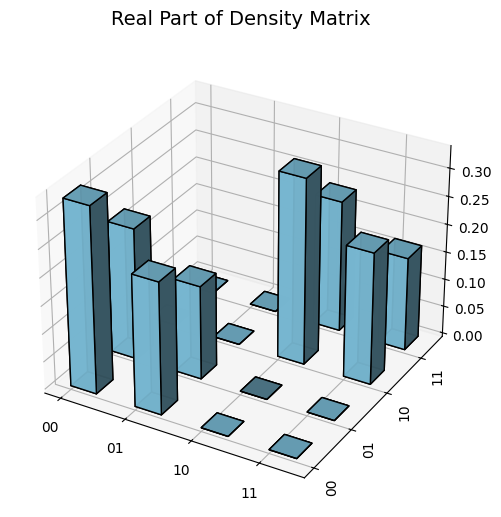

[[0.333+0.j    0.236-0.007j 0.   +0.j    0.   +0.j   ]
 [0.236+0.007j 0.167+0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.333+0.j    0.236-0.007j]
 [0.   +0.j    0.   +0.j    0.236+0.007j 0.167+0.j   ]]


In [92]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state()
# theta = 2 * np.pi * np.random.random()
rho = T_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

## **S Gate**

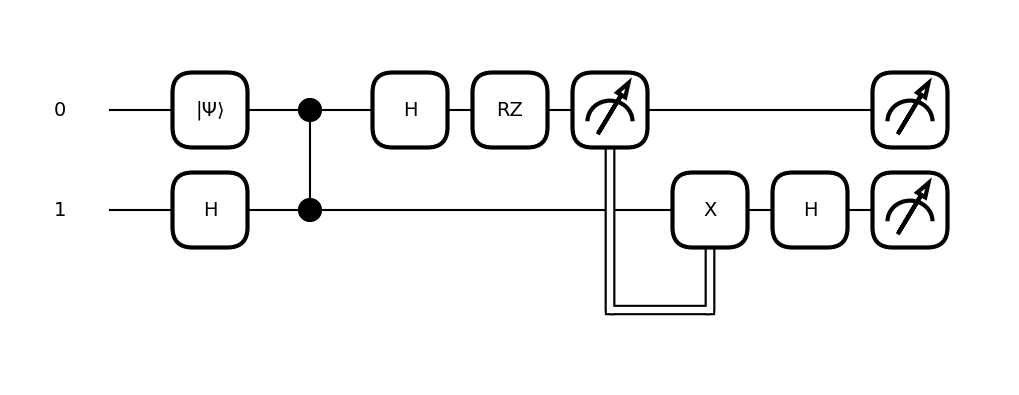

tensor([[0.5+0.j, 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0.5+0.j, 0. +0.j],
        [0. +0.j, 0. +0.j, 0. +0.j, 0. +0.j]], requires_grad=True)

In [94]:
dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def S(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.S(wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])

mbqc_dev = qml.device("default.qubit", wires=3)


@qml.qnode(mbqc_dev, interface="autograd")
def S_MBQC(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qml.Hadamard(wires=1)
    qml.CZ(wires=[0, 1])

    # Measure the first qubit and correct the state
    qml.Hadamard(wires=0)
    qml.RZ(np.pi/2,wires=0)
    m = qml.measure(wires=[0])

    qml.cond(m == 1, qml.PauliX)(wires=1)
    qml.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0, 1])



input_state = np.array([1.0, 0.0], dtype=complex)

# Generate a random input state


# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(S_MBQC)(input_state)
plt.show()

# print(S(input_state))
# print(S_MBQC(input_state))


S_MBQC(input_state)
#np.allclose(S(input_state), S_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


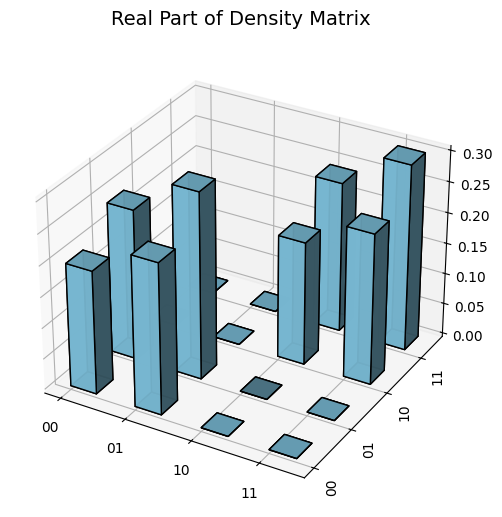

[[0.199+0.j    0.243+0.027j 0.   +0.j    0.   +0.j   ]
 [0.243-0.027j 0.301+0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.199+0.j    0.243+0.027j]
 [0.   +0.j    0.   +0.j    0.243-0.027j 0.301+0.j   ]]


In [95]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state()
# theta = 2 * np.pi * np.random.random()
rho = S_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

# **Unitary Operations for two qubit cluster**

$H|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$

$S|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} S_{0} CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$


$T|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} T_{0} CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$

<!-- $RX(\theta)|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} RX_{0}(\theta) CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$

$RY(\theta)|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} RY_{0}(\theta) CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$ -->

$RZ(\theta)|\psi_{\text{in}}\rangle_1 = X^{s^0} \langle \pm |_{0} RZ_{0}(\theta) CZ_{0,1} |+\rangle_1 \otimes |\psi_{\text{in}}\rangle_0$

### **For Three Qubit Cluster**

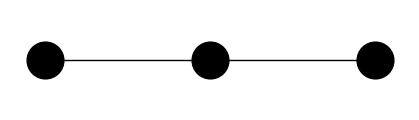

In [96]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 3  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(4, 1))
nx.draw(G, pos={node: node for node in G}, node_size=700, node_color="black")

## **T Gate**

In [97]:
import pennylane as qml

mbqc_dev = qml.device("default.qubit", wires=5)

@qml.qnode(mbqc_dev, interface="autograd")
def T_MBQC(input_state, theta):
    qml.StatePrep(input_state, wires=0)
    qml.Hadamard(wires=1)
    qml.Hadamard(wires=2)
    qml.CZ(wires=[0, 1])
    qml.CZ(wires=[1, 2])

    qml.RZ(theta, wires=0)
    qml.Hadamard(wires=0)
    m1 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    m2 = qml.measure(wires=1)

    qml.cond(m1 == 1,qml.PauliZ)(wires=2)
    qml.cond(m2 == 1, qml.PauliX)(wires=2)

    return qml.density_matrix(wires=[0,1,2])

input_state = generate_random_state()
theta =  np.pi/4


print(T_MBQC(input_state, theta))

[[ 0.09 +0.j    -0.028-0.117j  0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [-0.028+0.117j  0.16 +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.09 +0.j    -0.028-0.117j  0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j    -0.028+0.117j  0.16 +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.09 +0.j
  -0.028-0.117j  0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    -0.028+0.117j
   0.16 +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.09 +0.j    -0.028-0.117j]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j    -0.028+0.117j  0.16 +0.j   ]]


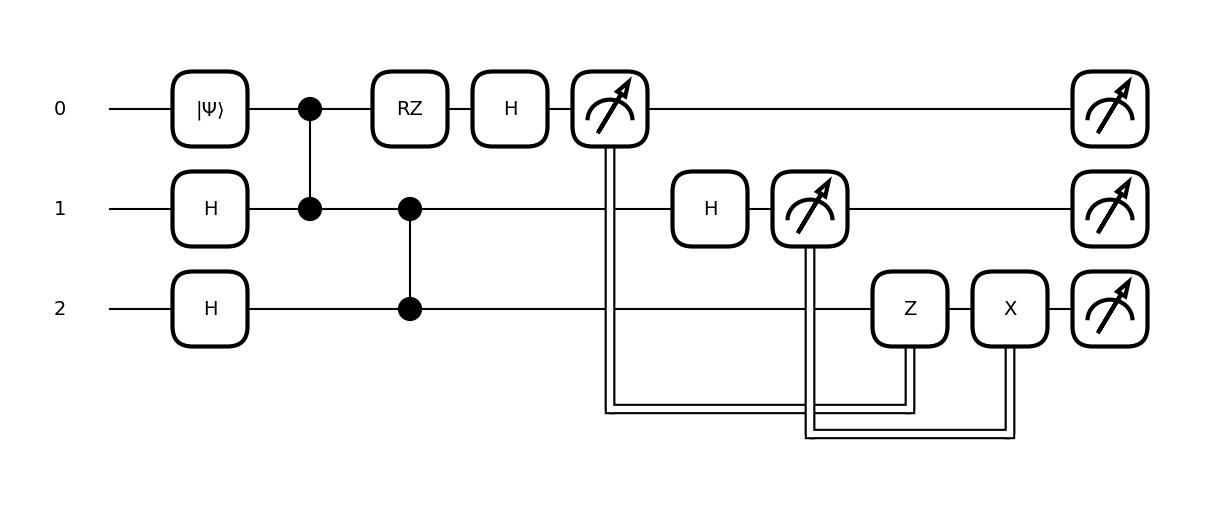

[[ 0.106+0.j    -0.034-0.119j  0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [-0.034+0.119j  0.144+0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.106+0.j    -0.034-0.119j  0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j    -0.034+0.119j  0.144+0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.106+0.j
  -0.034-0.119j  0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    -0.034+0.119j
   0.144+0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.106+0.j    -0.034-0.119j]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j    -0.034+0.119j  0.144+0.j   ]]


In [98]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt


# dev = qml.device("lightning.qubit", wires=1)


# @qml.qnode(dev, interface="autograd")
# def T(input_state):
#     # Prepare the input state
#     qml.StatePrep(input_state, wires=0)

#     # Perform the Rz rotation
#     qml.T(wires=0)

#     # Return the density matrix of the output state
#     return qml.density_matrix(wires=[0])


mbqc_dev = qml.device("default.qubit", wires=5)

# Define the QNode
@qml.qnode(mbqc_dev, interface="autograd")
def T_MBQC(input_state):
    qml.StatePrep(input_state, wires=0)


    # Create cluster state
    qml.Hadamard(wires=1)
    qml.Hadamard(wires=2)
    qml.CZ(wires=[0,1])
    qml.CZ(wires=[1,2])


    #measurement bases
    qml.RZ(theta,wires=0)
    qml.Hadamard(wires=0)
    m1 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    m2 = qml.measure(wires=1)

    qml.cond(m1 == 1,qml.PauliZ)(wires=2)
    qml.cond(m2 == 1, qml.PauliX)(wires=2)

    return qml.density_matrix(wires=[0,1,2])

# Define example inputs
input_state = generate_random_state()
theta =  np.pi/4

# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(T_MBQC)(input_state)
plt.show()


# print(T(input_state))
print(T_MBQC(input_state))

# np.allclose(T(input_state), T_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


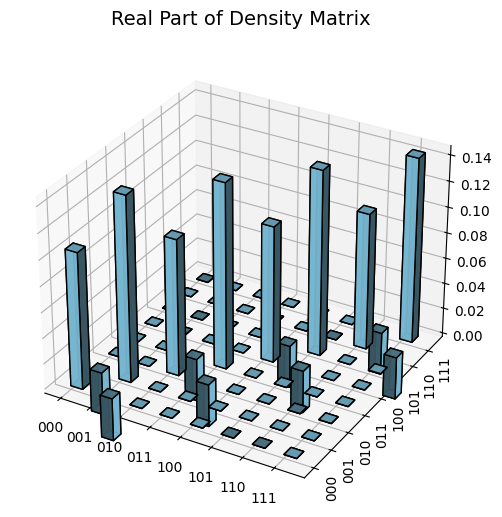

[[ 0.106+0.j    -0.034-0.119j  0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [-0.034+0.119j  0.144+0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.106+0.j    -0.034-0.119j  0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j    -0.034+0.119j  0.144+0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.106+0.j
  -0.034-0.119j  0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    -0.034+0.119j
   0.144+0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.106+0.j    -0.034-0.119j]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j    -0.034+0.119j  0.144+0.j   ]]


In [100]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['000', '001', '010', '011', '100', '101', '110', '111']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
rho = T_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

## **Hadamard Gate**

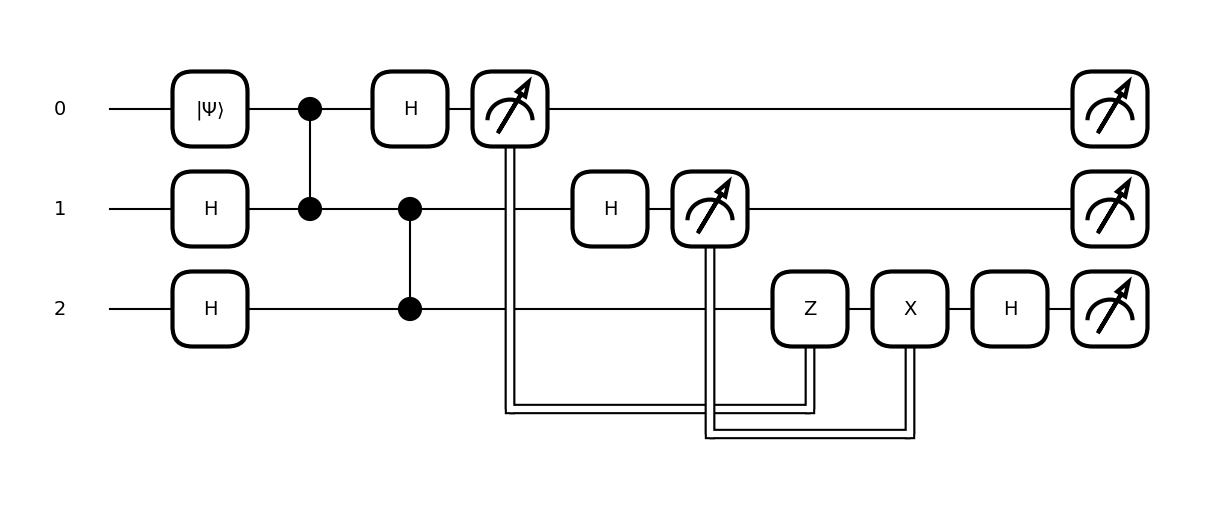

[[ 0.669+0.j    -0.453-0.126j]
 [-0.453+0.126j  0.331+0.j   ]]
[[ 0.167+0.j    -0.113-0.031j  0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [-0.113+0.031j  0.083+0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.167+0.j    -0.113-0.031j  0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j    -0.113+0.031j  0.083+0.j     0.   +0.j
   0.   +0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.167+0.j
  -0.113-0.031j  0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j    -0.113+0.031j
   0.083+0.j     0.   +0.j     0.   +0.j   ]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j     0.167+0.j    -0.113-0.031j]
 [ 0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j     0.   +0.j
   0.   +0.j    -0.113+0.031j  0.083+0.j   ]]


In [101]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt


dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def H(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.H(wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])


mbqc_dev = qml.device("default.qubit", wires=5)

# Define the QNode
@qml.qnode(mbqc_dev, interface="autograd")
def H_MBQC(input_state):
    qml.StatePrep(input_state, wires=0)


    # Create cluster state
    qml.Hadamard(wires=1)
    qml.Hadamard(wires=2)
    qml.CZ(wires=[0,1])
    qml.CZ(wires=[1,2])


    #measurement bases
    qml.Hadamard(wires=0)
    m1 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    m2 = qml.measure(wires=1)

    qml.cond(m1 == 1,qml.PauliZ)(wires=2)
    qml.cond(m2 == 1, qml.PauliX)(wires=2)

    qml.Hadamard(wires=2)

    return qml.density_matrix(wires=[0,1,2])

# Define example inputs
input_state = generate_random_state()
theta = 2 * np.pi * np.random.random()

# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(H_MBQC)(input_state)
plt.show()


print(H(input_state))
print(H_MBQC(input_state))

# np.allclose(H(input_state), H_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


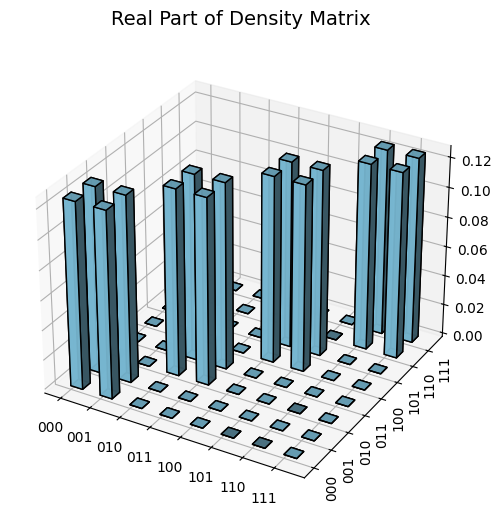

[[0.125+0.j 0.125+0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j
  0.   +0.j]
 [0.125+0.j 0.125+0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j
  0.   +0.j]
 [0.   +0.j 0.   +0.j 0.125+0.j 0.125+0.j 0.   +0.j 0.   +0.j 0.   +0.j
  0.   +0.j]
 [0.   +0.j 0.   +0.j 0.125+0.j 0.125+0.j 0.   +0.j 0.   +0.j 0.   +0.j
  0.   +0.j]
 [0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.125+0.j 0.125+0.j 0.   +0.j
  0.   +0.j]
 [0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.125+0.j 0.125+0.j 0.   +0.j
  0.   +0.j]
 [0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.125+0.j
  0.125+0.j]
 [0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.   +0.j 0.125+0.j
  0.125+0.j]]


In [102]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['000', '001', '010', '011', '100', '101', '110', '111']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
theta = np.pi / 4
input_state = np.array([1.0, 0.0], dtype=complex)
rho = H_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

## **S Gate**

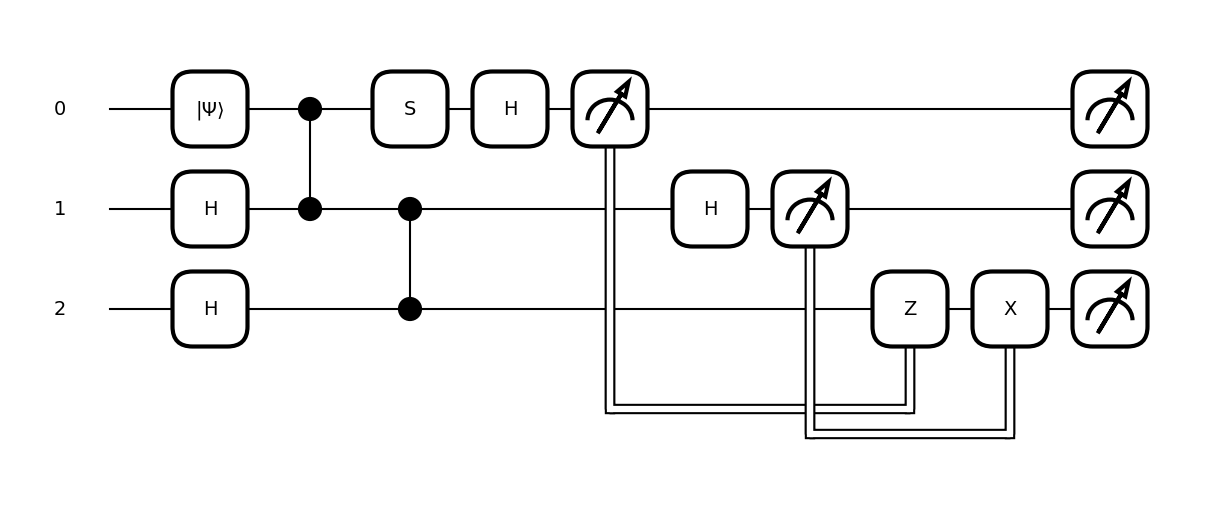

[[0.054+0.j    0.071-0.214j]
 [0.071+0.214j 0.946+0.j   ]]
[[0.013+0.j    0.018-0.053j 0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.018+0.053j 0.237+0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.013+0.j    0.018-0.053j 0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.018+0.053j 0.237+0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.013+0.j
  0.018-0.053j 0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.018+0.053j
  0.237+0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.013+0.j    0.018-0.053j]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.018+0.053j 0.237+0.j   ]]


In [103]:
import pennylane as qml
import pennylane.numpy as np
import matplotlib.pyplot as plt


dev = qml.device("lightning.qubit", wires=1)


@qml.qnode(dev, interface="autograd")
def S(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qml.S(wires=0)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0])


mbqc_dev = qml.device("default.qubit", wires=5)

# Define the QNode
@qml.qnode(mbqc_dev, interface="autograd")
def S_MBQC(input_state):
    qml.StatePrep(input_state, wires=0)


    # Create cluster state
    qml.Hadamard(wires=1)
    qml.Hadamard(wires=2)
    qml.CZ(wires=[0,1])
    qml.CZ(wires=[1,2])


    #measurement bases
    qml.S(wires=[0])
    qml.Hadamard(wires=0)
    m1 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    m2 = qml.measure(wires=1)

    qml.cond(m1 == 1,qml.PauliZ)(wires=2)
    qml.cond(m2 == 1, qml.PauliX)(wires=2)

    return qml.density_matrix(wires=[0,1,2])

# Define example inputs
input_state = generate_random_state()


# 🖼️ Plot circuit using qml.draw_mpl
fig, ax = qml.draw_mpl(S_MBQC)(input_state)
plt.show()


print(S(input_state))
print(S_MBQC(input_state))

# np.allclose(S(input_state), S_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


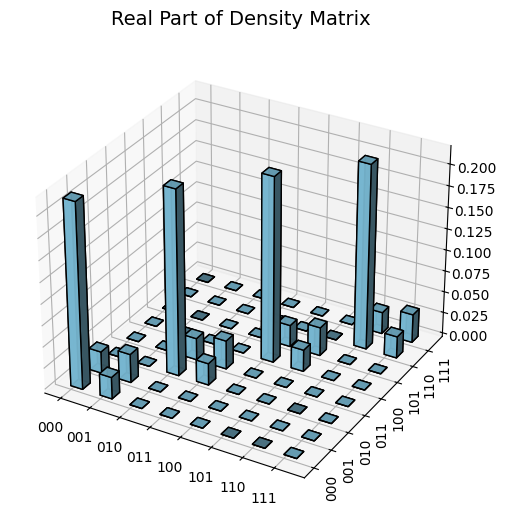

[[0.217+0.j    0.025+0.081j 0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.025-0.081j 0.033+0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.217+0.j    0.025+0.081j 0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.025-0.081j 0.033+0.j    0.   +0.j
  0.   +0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.217+0.j
  0.025+0.081j 0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.025-0.081j
  0.033+0.j    0.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.217+0.j    0.025+0.081j]
 [0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j    0.   +0.j
  0.   +0.j    0.025-0.081j 0.033+0.j   ]]


In [53]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['000', '001', '010', '011', '100', '101', '110', '111']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state()
rho = S_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

# **Double Qubit Gate Application**

## **CNOT Gate**

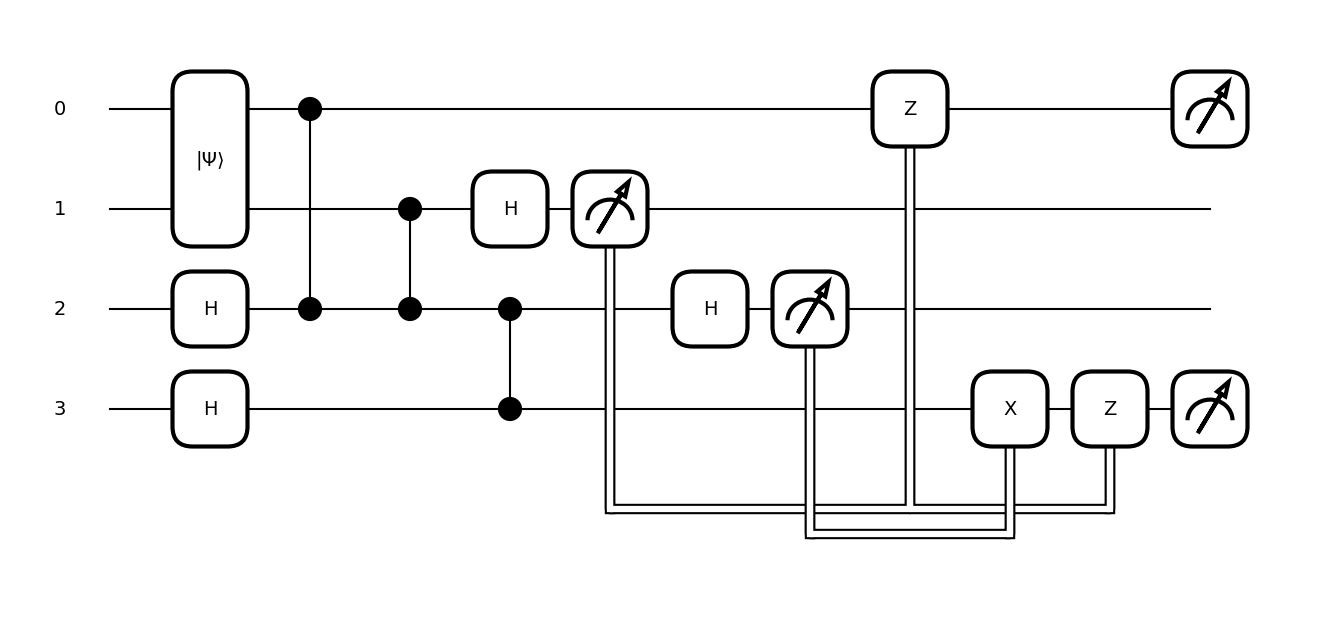

True

In [70]:
def generate_random_state(n=1):
    """Generate a random normalized n-qubit state"""
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)

dev = qml.device("lightning.qubit", wires=2)


@qml.qnode(dev, interface="autograd")
def CNOT(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=[0, 1])
    qml.CNOT(wires=[0, 1])

    return qml.density_matrix(wires=[0, 1])


mbqc_dev = qml.device("default.qubit", wires=4)

@qml.qnode(mbqc_dev, interface="autograd")
def CNOT_MBQC(input_state):
    # Prepare the input state
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare the cluster state
    qml.Hadamard(wires=2)
    qml.Hadamard(wires=3)
    qml.CZ(wires=[2, 0])
    qml.CZ(wires=[2, 1])
    qml.CZ(wires=[2, 3])

    # Measure the qubits in the appropriate bases
    qml.Hadamard(wires=1)
    m1 = qml.measure(wires=[1])
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=[2])

    # Correct the state
    qml.cond(m1 == 1, qml.PauliZ)(wires=0)
    qml.cond(m2 == 1, qml.PauliX)(wires=3)
    qml.cond(m1 == 1, qml.PauliZ)(wires=3)

    # Return the density matrix of the output state
    return qml.density_matrix(wires=[0,3])

input_state = generate_random_state(n=2)

# print(CNOT(input_state))
# print(CNOT_MBQC(input_state))


np.allclose(CNOT(input_state), CNOT_MBQC(input_state))

fig, ax = qml.draw_mpl(CNOT_MBQC)(input_state)
plt.show()


np.allclose(CNOT(input_state), CNOT_MBQC(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


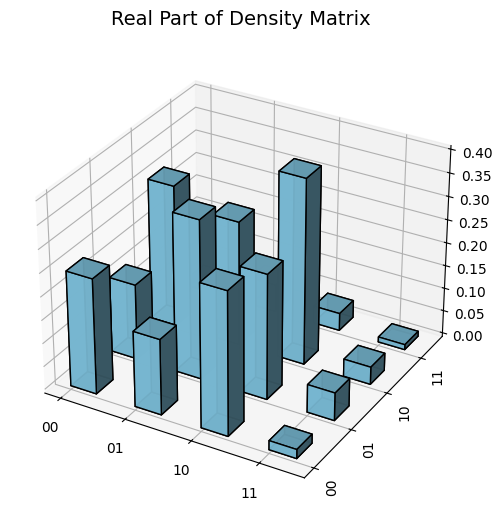

[[0.248+0.j    0.163+0.241j 0.307+0.069j 0.02 +0.049j]
 [0.163-0.241j 0.342+0.j    0.269-0.253j 0.06 +0.013j]
 [0.307-0.069j 0.269+0.253j 0.399+0.j    0.038+0.055j]
 [0.02 -0.049j 0.06 -0.013j 0.038-0.055j 0.011+0.j   ]]


In [71]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state(n=2)
rho = CNOT_MBQC(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)

## **CZ Gate**

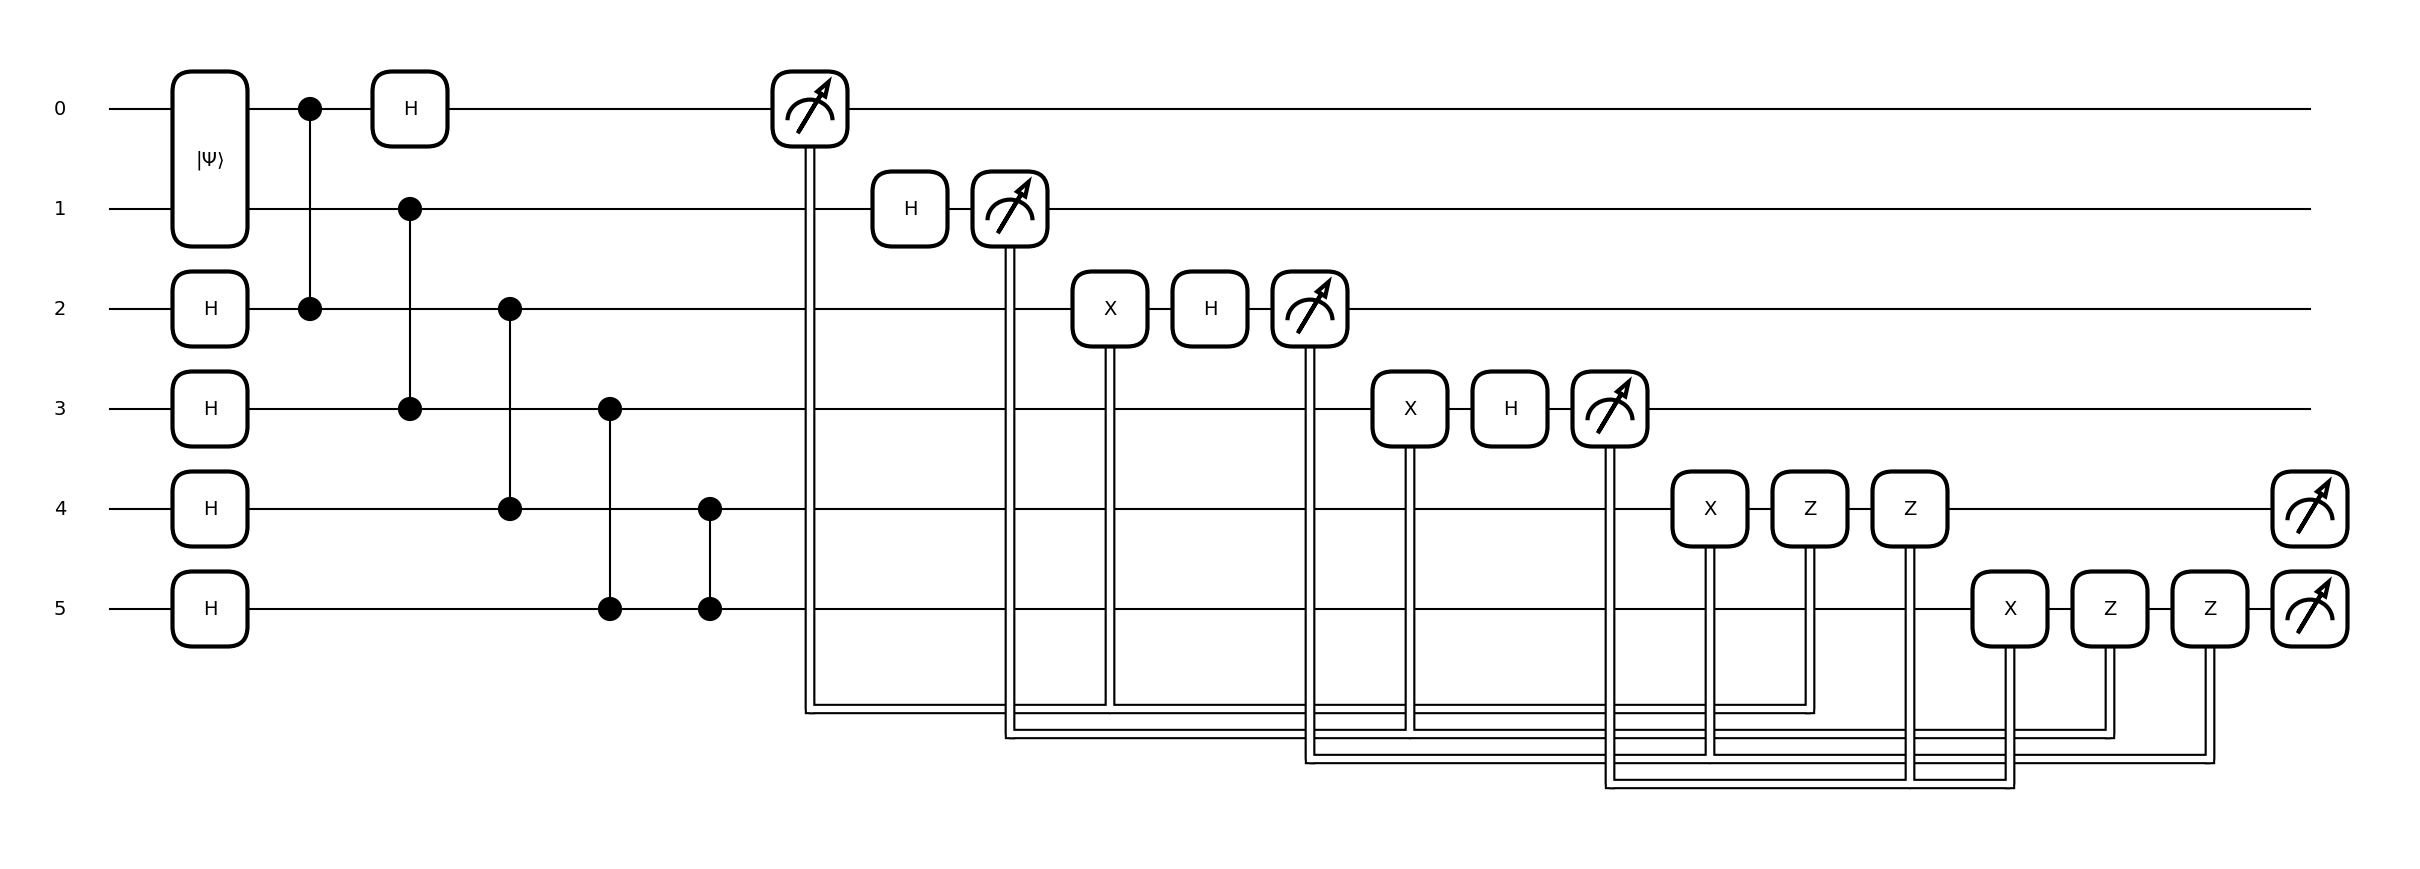

[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]
[[ 0.+0.j  0.+0.j  0.+0.j -0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j -0.+0.j  1.+0.j]]


True

In [72]:
import pennylane as qml
from pennylane import numpy as np


# Helper function to generate random normalized quantum states
def generate_random_state(n=1):
    """Generate a random normalized n-qubit state"""
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)


# Ideal CZ circuit
dev_cz = qml.device("lightning.qubit", wires=2)

@qml.qnode(dev_cz, interface="autograd")
def CZ(input_state):
    qml.StatePrep(input_state, wires=[0, 1])
    qml.CZ(wires=[0, 1])
    return qml.density_matrix(wires=[0, 1])


# MBQC CZ circuit
dev_mbqc = qml.device("default.qubit", wires=6)

@qml.qnode(dev_mbqc, interface="autograd")
def mbqc_cz(input_state):
    # Prepare the same input |ψ⟩ on qubits 0 and 1
    qml.StatePrep(input_state, wires=[0, 1])

    # Prepare ancilla cluster state (qubits 2, 3, 4, 5 in |+⟩ state)
    for w in [2, 3, 4, 5]:
        qml.Hadamard(wires=w)

    # Create cluster entanglement with CZ gates
    qml.CZ(wires=[0, 2])
    qml.CZ(wires=[1, 3])
    qml.CZ(wires=[2, 4])
    qml.CZ(wires=[3, 5])
    qml.CZ(wires=[4, 5])

    # Measure input qubits in X-basis (apply H then measure)
    qml.Hadamard(wires=0)
    m0 = qml.measure(wires=0)

    qml.Hadamard(wires=1)
    m1 = qml.measure(wires=1)

    # Measure ancilla qubits with byproduct corrections
    qml.cond(m0 == 1, qml.PauliX)(wires=2)
    qml.Hadamard(wires=2)
    m2 = qml.measure(wires=2)

    qml.cond(m1 == 1, qml.PauliX)(wires=3)
    qml.Hadamard(wires=3)
    m3 = qml.measure(wires=3)

    # Apply corrections to output qubits based on measurement outcomes
    qml.cond(m2 == 1, qml.PauliX)(wires=4)
    qml.cond(m0 == 1, qml.PauliZ)(wires=4)
    qml.cond(m3 == 1, qml.PauliZ)(wires=4)

    qml.cond(m3 == 1, qml.PauliX)(wires=5)
    qml.cond(m1 == 1, qml.PauliZ)(wires=5)
    qml.cond(m2 == 1, qml.PauliZ)(wires=5)

    # Return the density matrix of the logical output qubits (4, 5)
    return qml.density_matrix(wires=[4, 5])

input_state = np.array([0, 0, 0, 1], dtype=complex)

fig, ax = qml.draw_mpl(mbqc_cz)(input_state)
plt.show()


print(mbqc_cz(input_state))
print(CZ(input_state))

np.allclose(CZ(input_state), mbqc_cz(input_state))

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


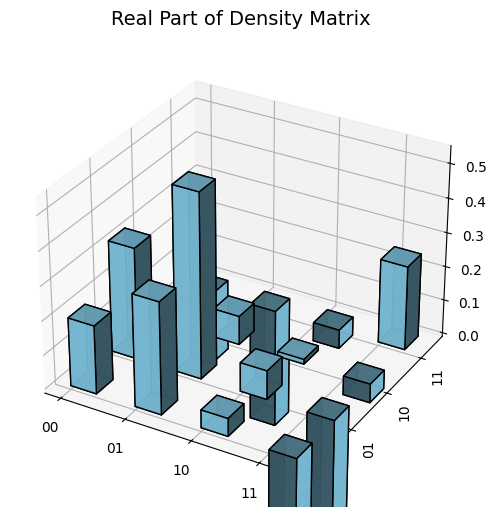

[[ 0.2  +0.j     0.327-0.033j  0.052+0.005j -0.217+0.047j]
 [ 0.327+0.033j  0.539+0.j     0.084+0.017j -0.363+0.04j ]
 [ 0.052-0.005j  0.084-0.017j  0.014+0.j    -0.056+0.018j]
 [-0.217-0.047j -0.363-0.04j  -0.056-0.018j  0.247+0.j   ]]


In [73]:
def plot_density_matrix_3d_simple(rho):
    fig = plt.figure(figsize=(7, 6), layout='constrained')
    ax = fig.add_subplot(111, projection='3d')

    n = rho.shape[0]
    xpos, ypos = np.meshgrid(np.arange(n), np.arange(n))
    xpos = xpos.flatten()
    ypos = ypos.flatten()
    zpos = np.zeros_like(xpos)

    dx = dy = 0.4
    dz = np.real(rho.flatten())

    ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color='skyblue', edgecolor='black', alpha=0.95)

    # Basis state labels for 2-qubit system
    basis_labels = ['00', '01', '10', '11']
    ax.set_xticks(range(n))
    ax.set_xticklabels(basis_labels, fontsize=10, rotation=0, ha='center')

    ax.set_yticks(range(n))
    ax.set_yticklabels(basis_labels, fontsize=10, rotation=90, va='center', ha='center')

    ax.set_zlabel('Re(ρ)', labelpad=12)
    ax.set_title('Real Part of Density Matrix', fontsize=14, pad=15)

    plt.show()

# Run the circuit and plot
input_state = generate_random_state(n=2)
rho = mbqc_cz(input_state)

plot_density_matrix_3d_simple(rho)

print(rho)